# 03 — Imbalance-Aware Classification (Family A)
Models that directly learn the employed/unemployed boundary. Each
handles the ~80/20 imbalance differently: class weighting (A1),
a boosting-specific weight parameter (A2), and oversampling (A3, A4).

A2–A4 require `xgboost` / `imbalanced-learn`. Two reference baselines
(a prior-only dummy and a class-weighted logistic regression) are run
under the same CV at the end of this notebook.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import display

from sklearn.model_selection import train_test_split

from src.feature_engineering import CANDIDATE_FEATURES, NUMERIC_FEATURES, NOMINAL_FEATURES, TARGET_COLUMN
from src.classification_models import build_classification_models, build_baseline_models
from src.evaluation import (
    compare_models, get_out_of_fold_probabilities, find_best_threshold,
    evaluate_on_holdout, plot_precision_recall_curves, plot_confusion_matrix
)
from src.reporting import TABLES_DIR, save_table

RANDOM_STATE = 42
TEST_SIZE = 0.2

In [2]:
df_final = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "tracer_study_processed.csv")

X = df_final[CANDIDATE_FEATURES]
y = df_final[TARGET_COLUMN].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
display(y_train.value_counts(normalize=True).round(3))

Train: (125, 11), Test: (32, 11)


employment_status
1    0.8
0    0.2
Name: proportion, dtype: float64

## Build Family A models

Modeling uses the reduced, leakage-checked 11-variable feature set in
`CANDIDATE_FEATURES` (`src/feature_engineering.py`) — the original ~20-variable
set gave only ~1.5 minority-class events per predictor (31 unemployed cases),
well below the 10-20:1 guideline, and included two composite indices rated
*after* employment status in the same survey (`employability_index`,
`retrospective_choice_index`), which risked target leakage. See the README's
"Feature set" section for the full rationale.

Set `include_xgboost`/`include_smote`/`include_adasyn` to `False` below if
`xgboost`/`imbalanced-learn` aren't installed in your environment.

In [3]:
INCLUDE_XGBOOST = True   # set True if xgboost is installed
INCLUDE_SMOTE = True     # set True if imbalanced-learn is installed
INCLUDE_ADASYN = True    # set True if imbalanced-learn is installed

models = build_classification_models(
    NUMERIC_FEATURES, NOMINAL_FEATURES, y_train=y_train,
    include_xgboost=INCLUDE_XGBOOST,
    include_smote=INCLUDE_SMOTE,
    include_adasyn=INCLUDE_ADASYN
)

print("Models built:", list(models.keys()))
print("\nTo run the full four-model comparison the thesis specifies, "
      "install xgboost + imbalanced-learn and set all three flags to True.")

Models built: ['A1_RandomForest_ClassWeighted', 'A2_XGBoost_ScalePosWeight', 'A3_SMOTE_RandomForest', 'A4_ADASYN_RandomForest']

To run the full four-model comparison the thesis specifies, install xgboost + imbalanced-learn and set all three flags to True.


## Repeated Stratified 5-Fold Cross-Validation (PR-AUC primary)

10 repeats, per the study's evaluation design — reduces the noise a
single 5-fold split would carry at this sample size (n≈125 training
rows).

In [4]:
summary_table, raw_scores = compare_models(models, X_train, y_train)
display(summary_table.round(3))

,accuracy,precision,recall,f1,pr_auc,roc_auc,accuracy_std,precision_std,recall_std,f1_std,pr_auc_std,roc_auc_std,pr_auc_ci_low,pr_auc_ci_high,pr_auc_corrected_ci_low,pr_auc_corrected_ci_high,base_rate
A4_ADASYN_RandomForest,0.759,0.368,0.228,0.266,0.440,0.673,0.070,0.288,0.150,0.171,0.114,0.101,0.408,0.471,0.319,0.560,0.2
A3_SMOTE_RandomForest,0.758,0.358,0.256,0.276,0.432,0.667,0.069,0.280,0.192,0.186,0.114,0.116,0.401,0.464,0.312,0.552,0.2
A1_RandomForest_ClassWeighted,0.731,0.352,0.364,0.343,0.426,0.656,0.081,0.189,0.199,0.167,0.126,0.107,0.392,0.461,0.293,0.558,0.2
A2_XGBoost_ScalePosWeight,0.690,0.298,0.352,0.302,0.386,0.613,0.084,0.192,0.190,0.144,0.136,0.133,0.350,0.426,0.243,0.529,0.2


## Threshold tuning and holdout evaluation (best model)

Threshold chosen from **out-of-fold** predictions only — the
holdout set stays untouched until this final check, so it isn't
used to pick the threshold, only to report on it.

In [5]:
best_name = summary_table.index[0]
best_model = models[best_name]
print(f"Best model (by CV PR-AUC): {best_name}")

oof_proba = get_out_of_fold_probabilities(best_model, X_train, y_train)
threshold, cv_prec, cv_rec, cv_f1 = find_best_threshold(y_train, oof_proba, metric="f1")
print(f"Tuned threshold: {threshold:.3f}  (OOF precision={cv_prec:.3f}, recall={cv_rec:.3f}, f1={cv_f1:.3f})")

best_model.fit(X_train, y_train)
holdout_default = evaluate_on_holdout(best_model, X_test, y_test, threshold=0.5)
holdout_tuned = evaluate_on_holdout(best_model, X_test, y_test, threshold=threshold)

holdout_table = pd.DataFrame({"default (0.5)": holdout_default, "tuned": holdout_tuned})
display(holdout_table.round(3))
save_table(holdout_table, "family_a_holdout");

Best model (by CV PR-AUC): A4_ADASYN_RandomForest


Tuned threshold: 0.200  (OOF precision=0.264, recall=0.760, f1=0.392)


,default (0.5),tuned
accuracy,0.688,0.438
precision,0.000,0.071
recall,0.000,0.167
f1,0.000,0.100
pr_auc,0.171,0.171
roc_auc,0.212,0.212
base_rate,0.188,0.188
threshold_used,0.500,0.200


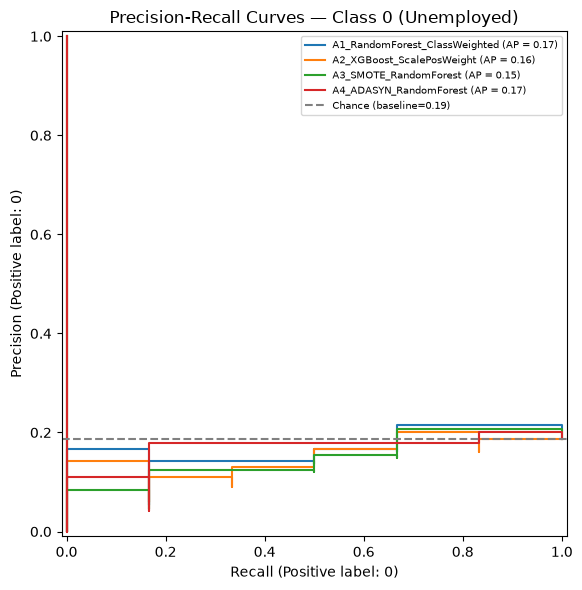

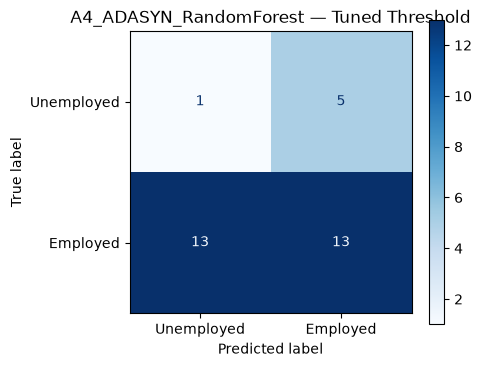

In [6]:
for m in models.values():
    m.fit(X_train, y_train)

plot_precision_recall_curves(models, X_test, y_test, save_as="family_a_pr_curves")
plot_confusion_matrix(best_model, X_test, y_test, threshold=threshold,
                       title=f"{best_name} — Tuned Threshold",
                       save_as="family_a_confusion_matrix")

## Save results for `05_evaluation.ipynb`

In [7]:
save_table(summary_table, "family_a_cv_summary")

import pickle
with open(TABLES_DIR / "family_a_raw_scores.pkl", "wb") as f:
    pickle.dump(raw_scores, f)

print("Saved Family A results to reports/tables/")

Saved Family A results to reports/tables/


## Reference baselines

Same CV folds as above. `BL1_Dummy_Prior` scores the base rate (PR-AUC's
chance level); `BL2_LogReg_Balanced` is the simple model the Random
Forest / resampling variants need to beat. Saved separately so they
never compete for "best Family A model".

In [8]:
baselines = build_baseline_models(NUMERIC_FEATURES, NOMINAL_FEATURES)
baseline_summary, baseline_scores = compare_models(baselines, X_train, y_train)
display(baseline_summary.round(3))

save_table(baseline_summary, "baseline_cv_summary")
with open(TABLES_DIR / "baseline_raw_scores.pkl", "wb") as f:
    pickle.dump(baseline_scores, f)

,accuracy,precision,recall,f1,pr_auc,roc_auc,accuracy_std,precision_std,recall_std,f1_std,pr_auc_std,roc_auc_std,pr_auc_ci_low,pr_auc_ci_high,pr_auc_corrected_ci_low,pr_auc_corrected_ci_high,base_rate
BL2_LogReg_Balanced,0.618,0.274,0.5,0.342,0.385,0.663,0.118,0.161,0.257,0.171,0.155,0.131,0.344,0.428,0.221,0.549,0.2
BL1_Dummy_Prior,0.800,0.000,0.0,0.000,0.200,0.500,0.000,0.000,0.000,0.000,0.000,0.000,0.200,0.200,0.200,0.200,0.2
